In [94]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [95]:
in_dir = '../../results/03_kidney_atlas/02_create_anndata'
out_dir = '../../results/03_kidney_atlas/05_find_markers'

os.makedirs(out_dir, exist_ok=True)

In [96]:
adata = sc.read_h5ad(f'{in_dir}/adata.h5ad')

In [97]:
adata

AnnData object with n_obs × n_vars = 203702 × 29732
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure'
    var: 'genes'
    uns: 'condition.l3_colors', 'laterality_colors', 'location_colors', 'patient_colors', 'structure_colors', 'subclass.l2_colors'
    obsm: 'X_umap'

In [98]:
adata.obs['subclass.l1'] = adata.obs['subclass.l1'].astype(str)
adata.obs['subclass.l2'] = adata.obs['subclass.l2'].astype(str)
adata = adata[adata.obs['subclass.l1'] != "nan"].copy()
adata = adata[adata.obs['subclass.l2'] != "nan"].copy()

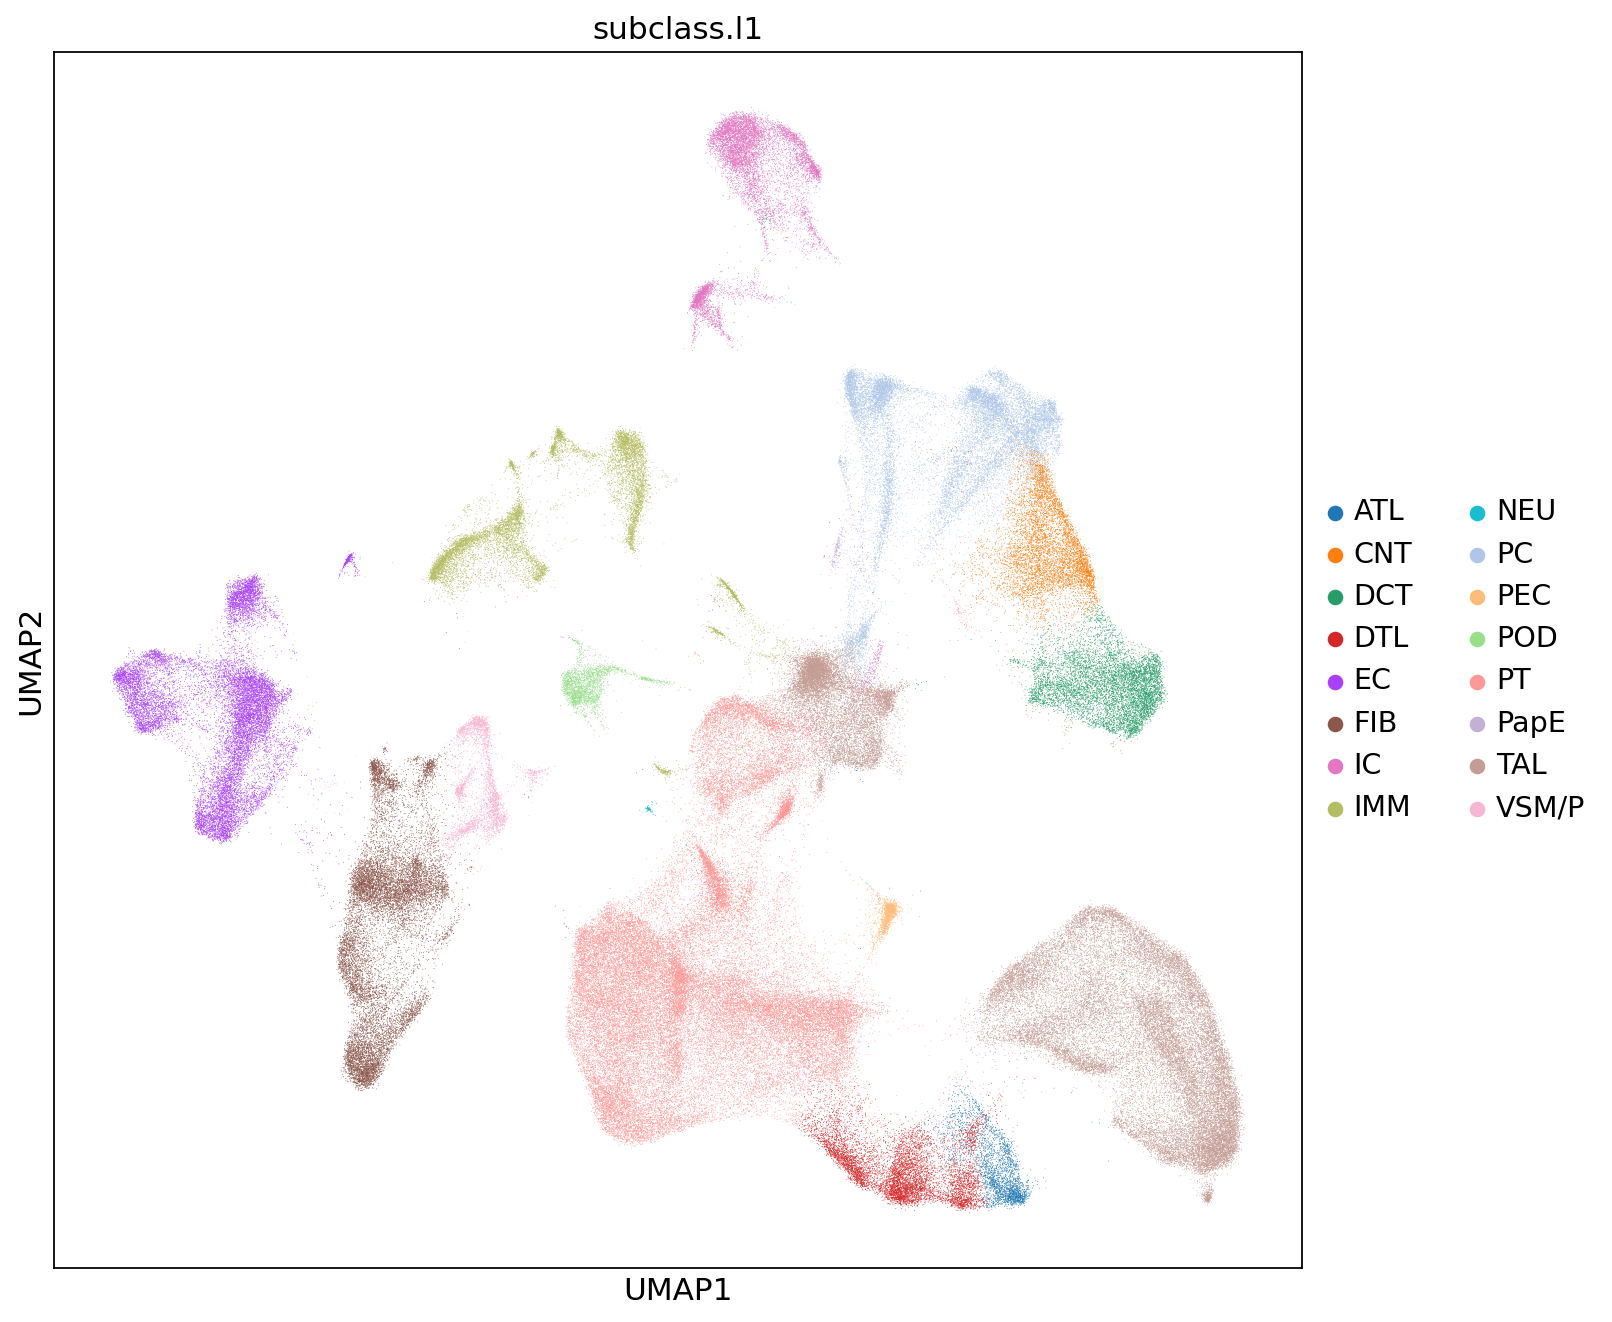

In [99]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color='subclass.l1')

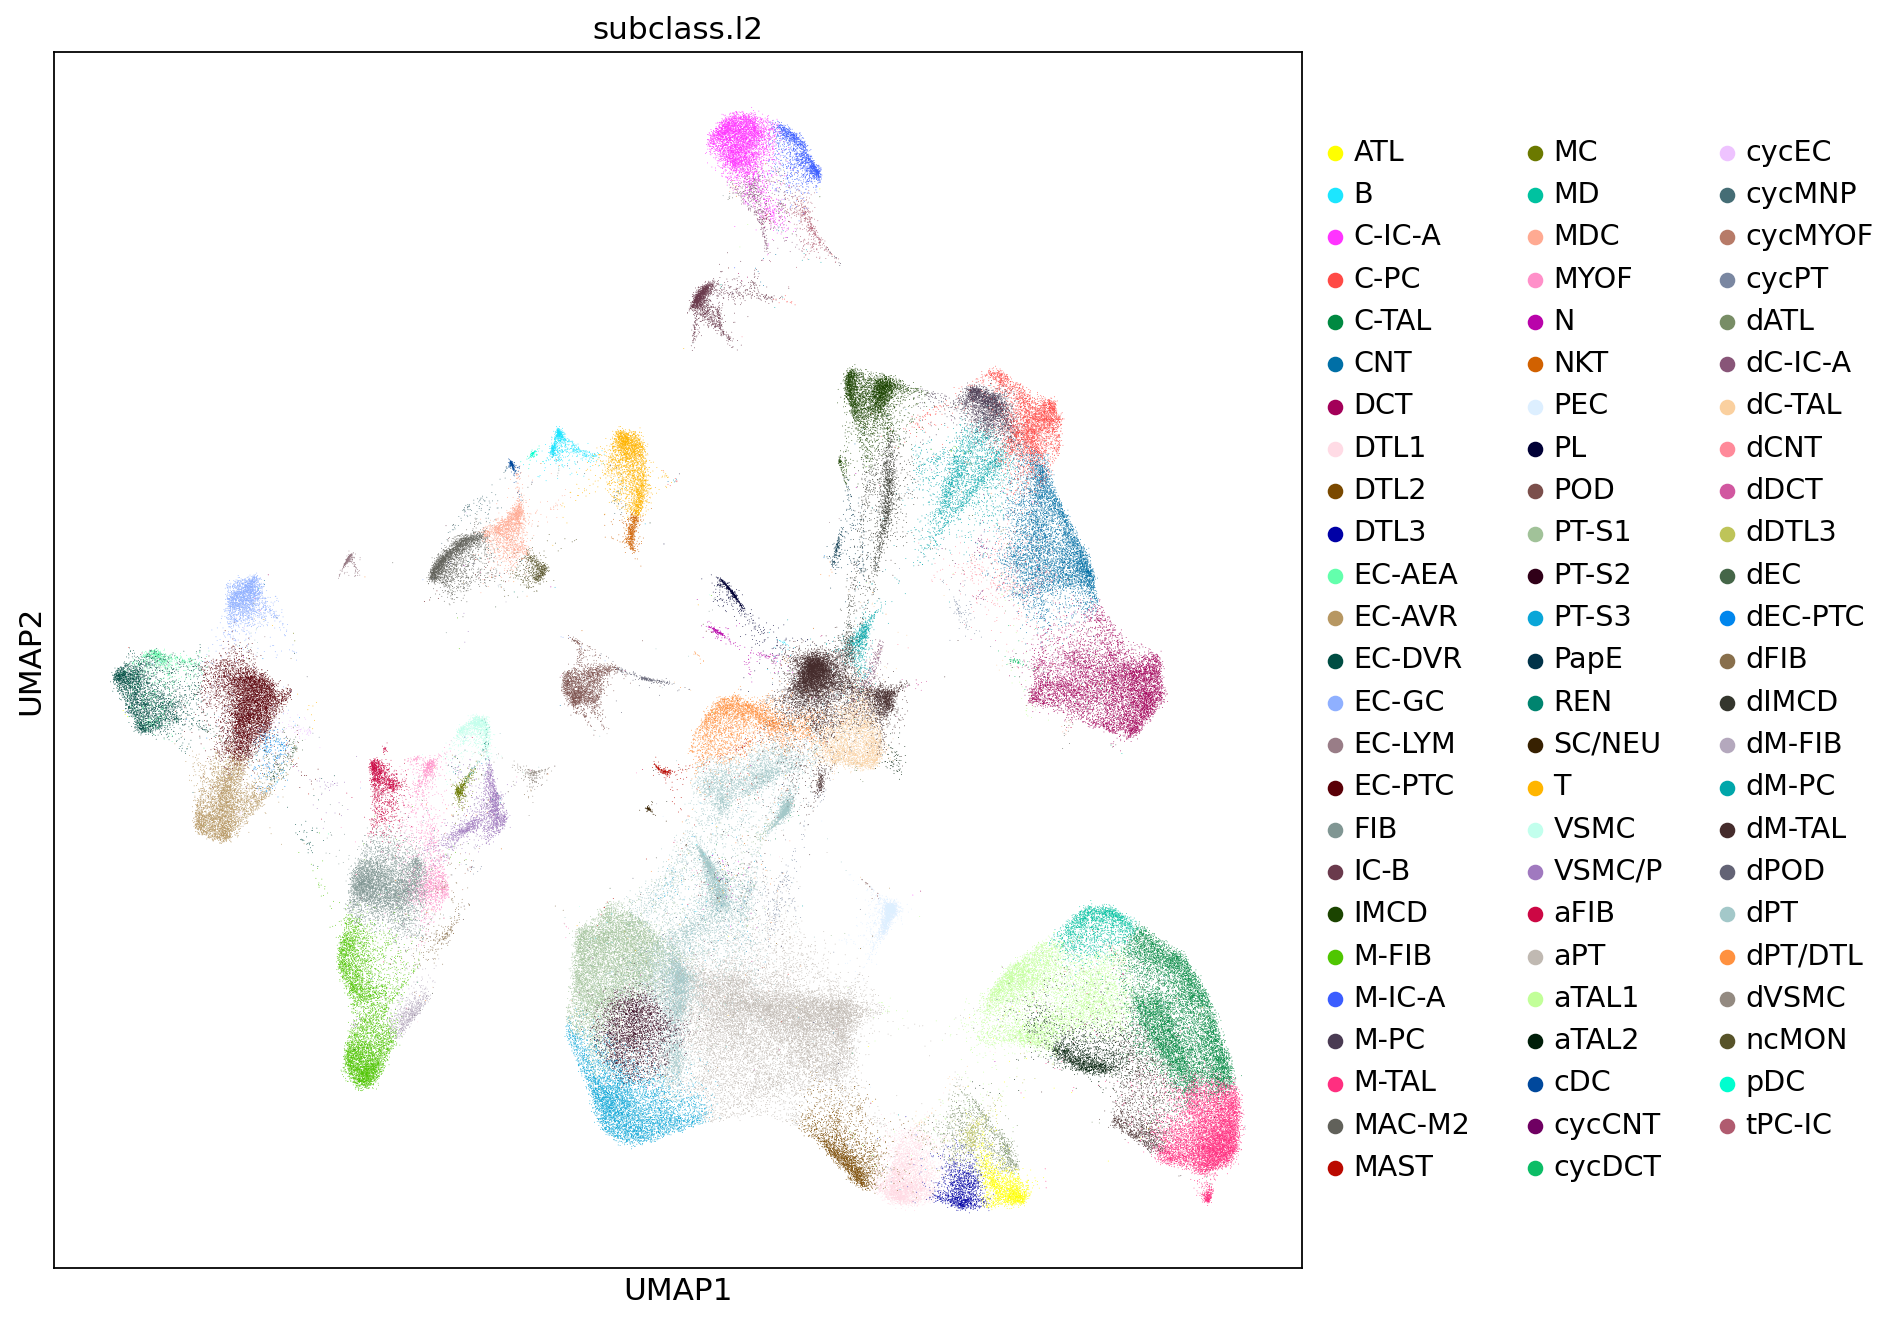

In [100]:
sc.pl.umap(adata, color='subclass.l2')

In [101]:
adata.layers["counts"] = adata.X.copy()

In [102]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [103]:
sc.pp.filter_genes(adata, min_cells=int(0.01 * adata.n_obs))

In [104]:
adata

AnnData object with n_obs × n_vars = 200338 × 15382
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct

In [105]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [106]:
sc.tl.rank_genes_groups(
    adata,
    groupby='subclass.l1',   # the categorical variable
    method='wilcoxon',     # 't-test', 't-test_overestim_var', or 'wilcoxon'
    key_added='rank_genes_subclass_l1'  # the name of the new column in adata.uns
)

In [107]:
# Convert to a pandas DataFrame
markers_df = sc.get.rank_genes_groups_df(adata, None, key='rank_genes_subclass_l1')  # all groups
# Keep top 50 per cell type
markers_df = (
    markers_df.groupby('group', group_keys=False)
    .apply(lambda x: x.nlargest(100, 'logfoldchanges'))
)

In [108]:
df = pd.read_csv(f'../../results/03_kidney_atlas/03_run_cell2location/subclass_l1/inf_aver.csv', index_col=0)
df = df.loc[markers_df['names'].unique(), :]
df.to_csv(f'{out_dir}/marker_genes_subclass_l1.csv')

In [109]:
df.head()

,ATL,CNT,DCT,DTL,EC,FIB,IC,IMM,NEU,PC,PEC,POD,PT,PapE,TAL,VSM/P
SH3GL3,6.417988,0.010656,0.007495,0.592298,0.000380,0.002929,0.009878,0.001348,0.041162,0.039021,0.007228,0.002668,0.002544,0.011401,0.021784,0.000771
ABCA4,2.717324,0.118829,0.024105,0.591518,0.013650,0.010717,0.017492,0.002449,0.025087,0.213647,0.030405,0.031199,0.003065,0.020935,0.083181,0.003141
BCAS1,1.638150,0.025894,0.016065,0.506776,0.003159,0.002515,0.012366,0.009503,0.025264,0.080567,0.012990,0.005432,0.004739,2.434469,0.111550,0.001679
FGF18,0.252321,0.001102,0.003317,0.048382,0.024890,0.004318,0.002300,0.001919,0.021730,0.008903,0.001329,0.001871,0.000178,0.020758,0.003538,0.004239
CNTD2,0.707956,0.001045,0.003689,0.220187,0.000377,0.000686,0.002292,0.000538,0.024238,0.003232,0.001278,0.011056,0.003781,0.009724,0.041389,0.001051


Text(279.42676767676767, 0.5, 'Genes')

<Figure size 800x640 with 0 Axes>

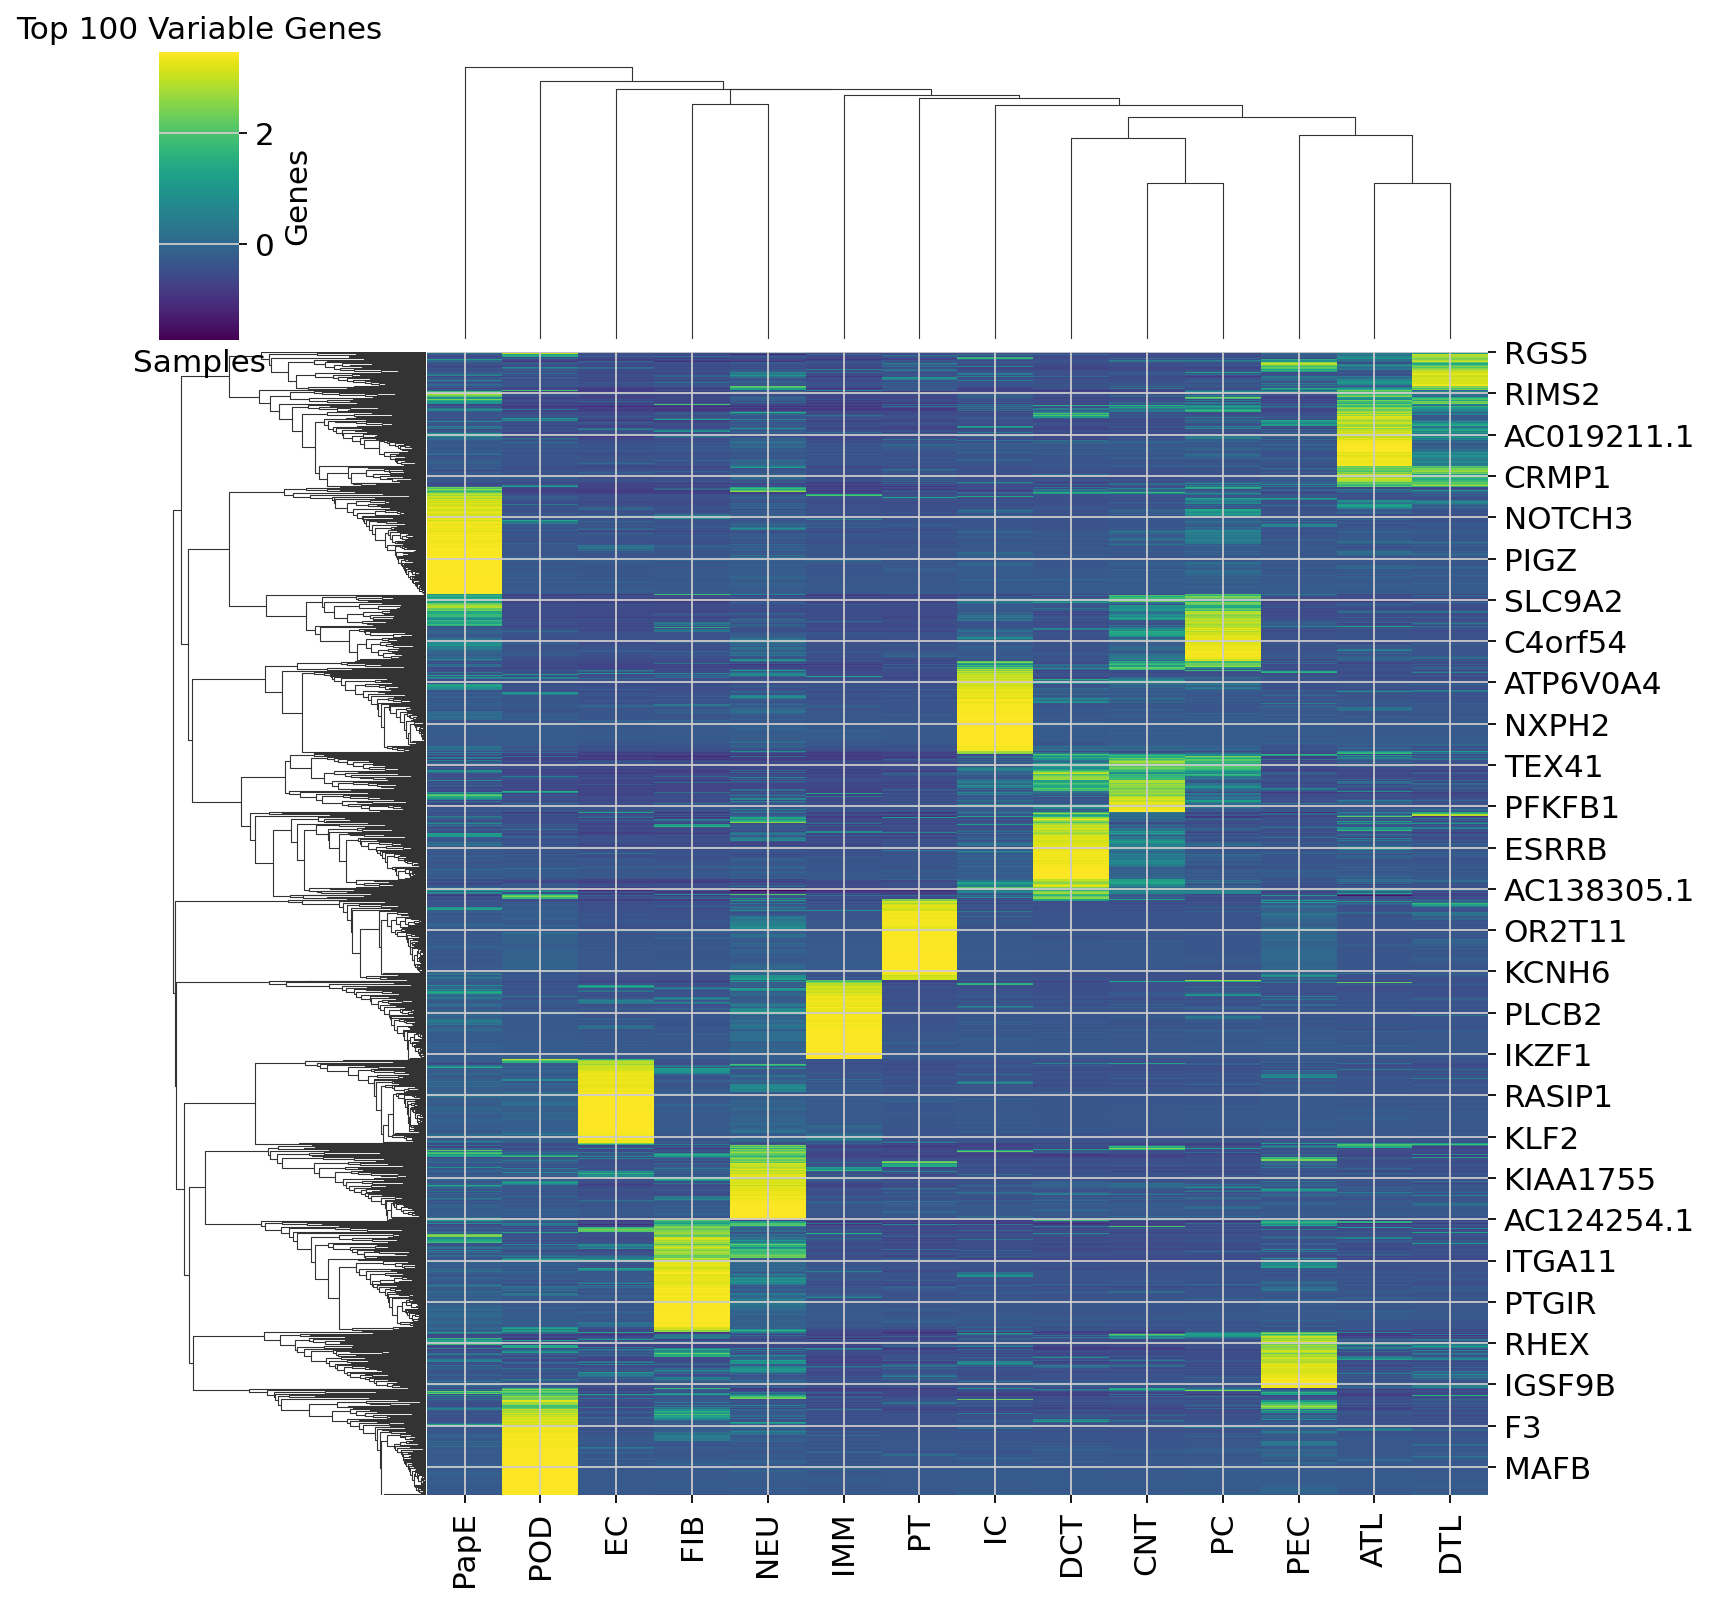

In [110]:
# first normalize the data for better visualization z-score normalization
df.iloc[:, :-2] = (df.iloc[:, :-2] - df.iloc[:, :-2].mean(axis=1).values[:, None]) / df.iloc[:, :-2].std(axis=1).values[:, None]

plt.figure(figsize=(10, 8))
sns.clustermap(df.iloc[:, :-2], cmap='viridis')
plt.title('Top 100 Variable Genes')
plt.xlabel('Samples')
plt.ylabel('Genes')

In [111]:
sc.tl.rank_genes_groups(
    adata,
    groupby='subclass.l2',   # the categorical variable
    method='wilcoxon',     # 't-test', 't-test_overestim_var', or 'wilcoxon'
    key_added='rank_genes_subclass_l2'  # the name of the new column in adata.uns
)

In [112]:
# Convert to a pandas DataFrame
markers_df = sc.get.rank_genes_groups_df(adata, None, key='rank_genes_subclass_l2')  # all groups

# Keep top 50 per cell type
markers_df = (
    markers_df.groupby('group', group_keys=False)
    .apply(lambda x: x.nlargest(100, 'logfoldchanges'))
)

In [113]:
df = pd.read_csv(f'../../results/03_kidney_atlas/03_run_cell2location/subclass_l2/inf_aver.csv', index_col=0)
df = df.loc[markers_df['names'].unique(), :]
df.to_csv(f'{out_dir}/marker_genes_subclass_l2.csv')

In [114]:
# first normalize the data for better visualization z-score normalization
df.iloc[:, :-2] = (df.iloc[:, :-2] - df.iloc[:, :-2].mean(axis=1).values[:, None]) / df.iloc[:, :-2].std(axis=1).values[:, None]

Text(279.67676767676767, 0.5, 'Genes')

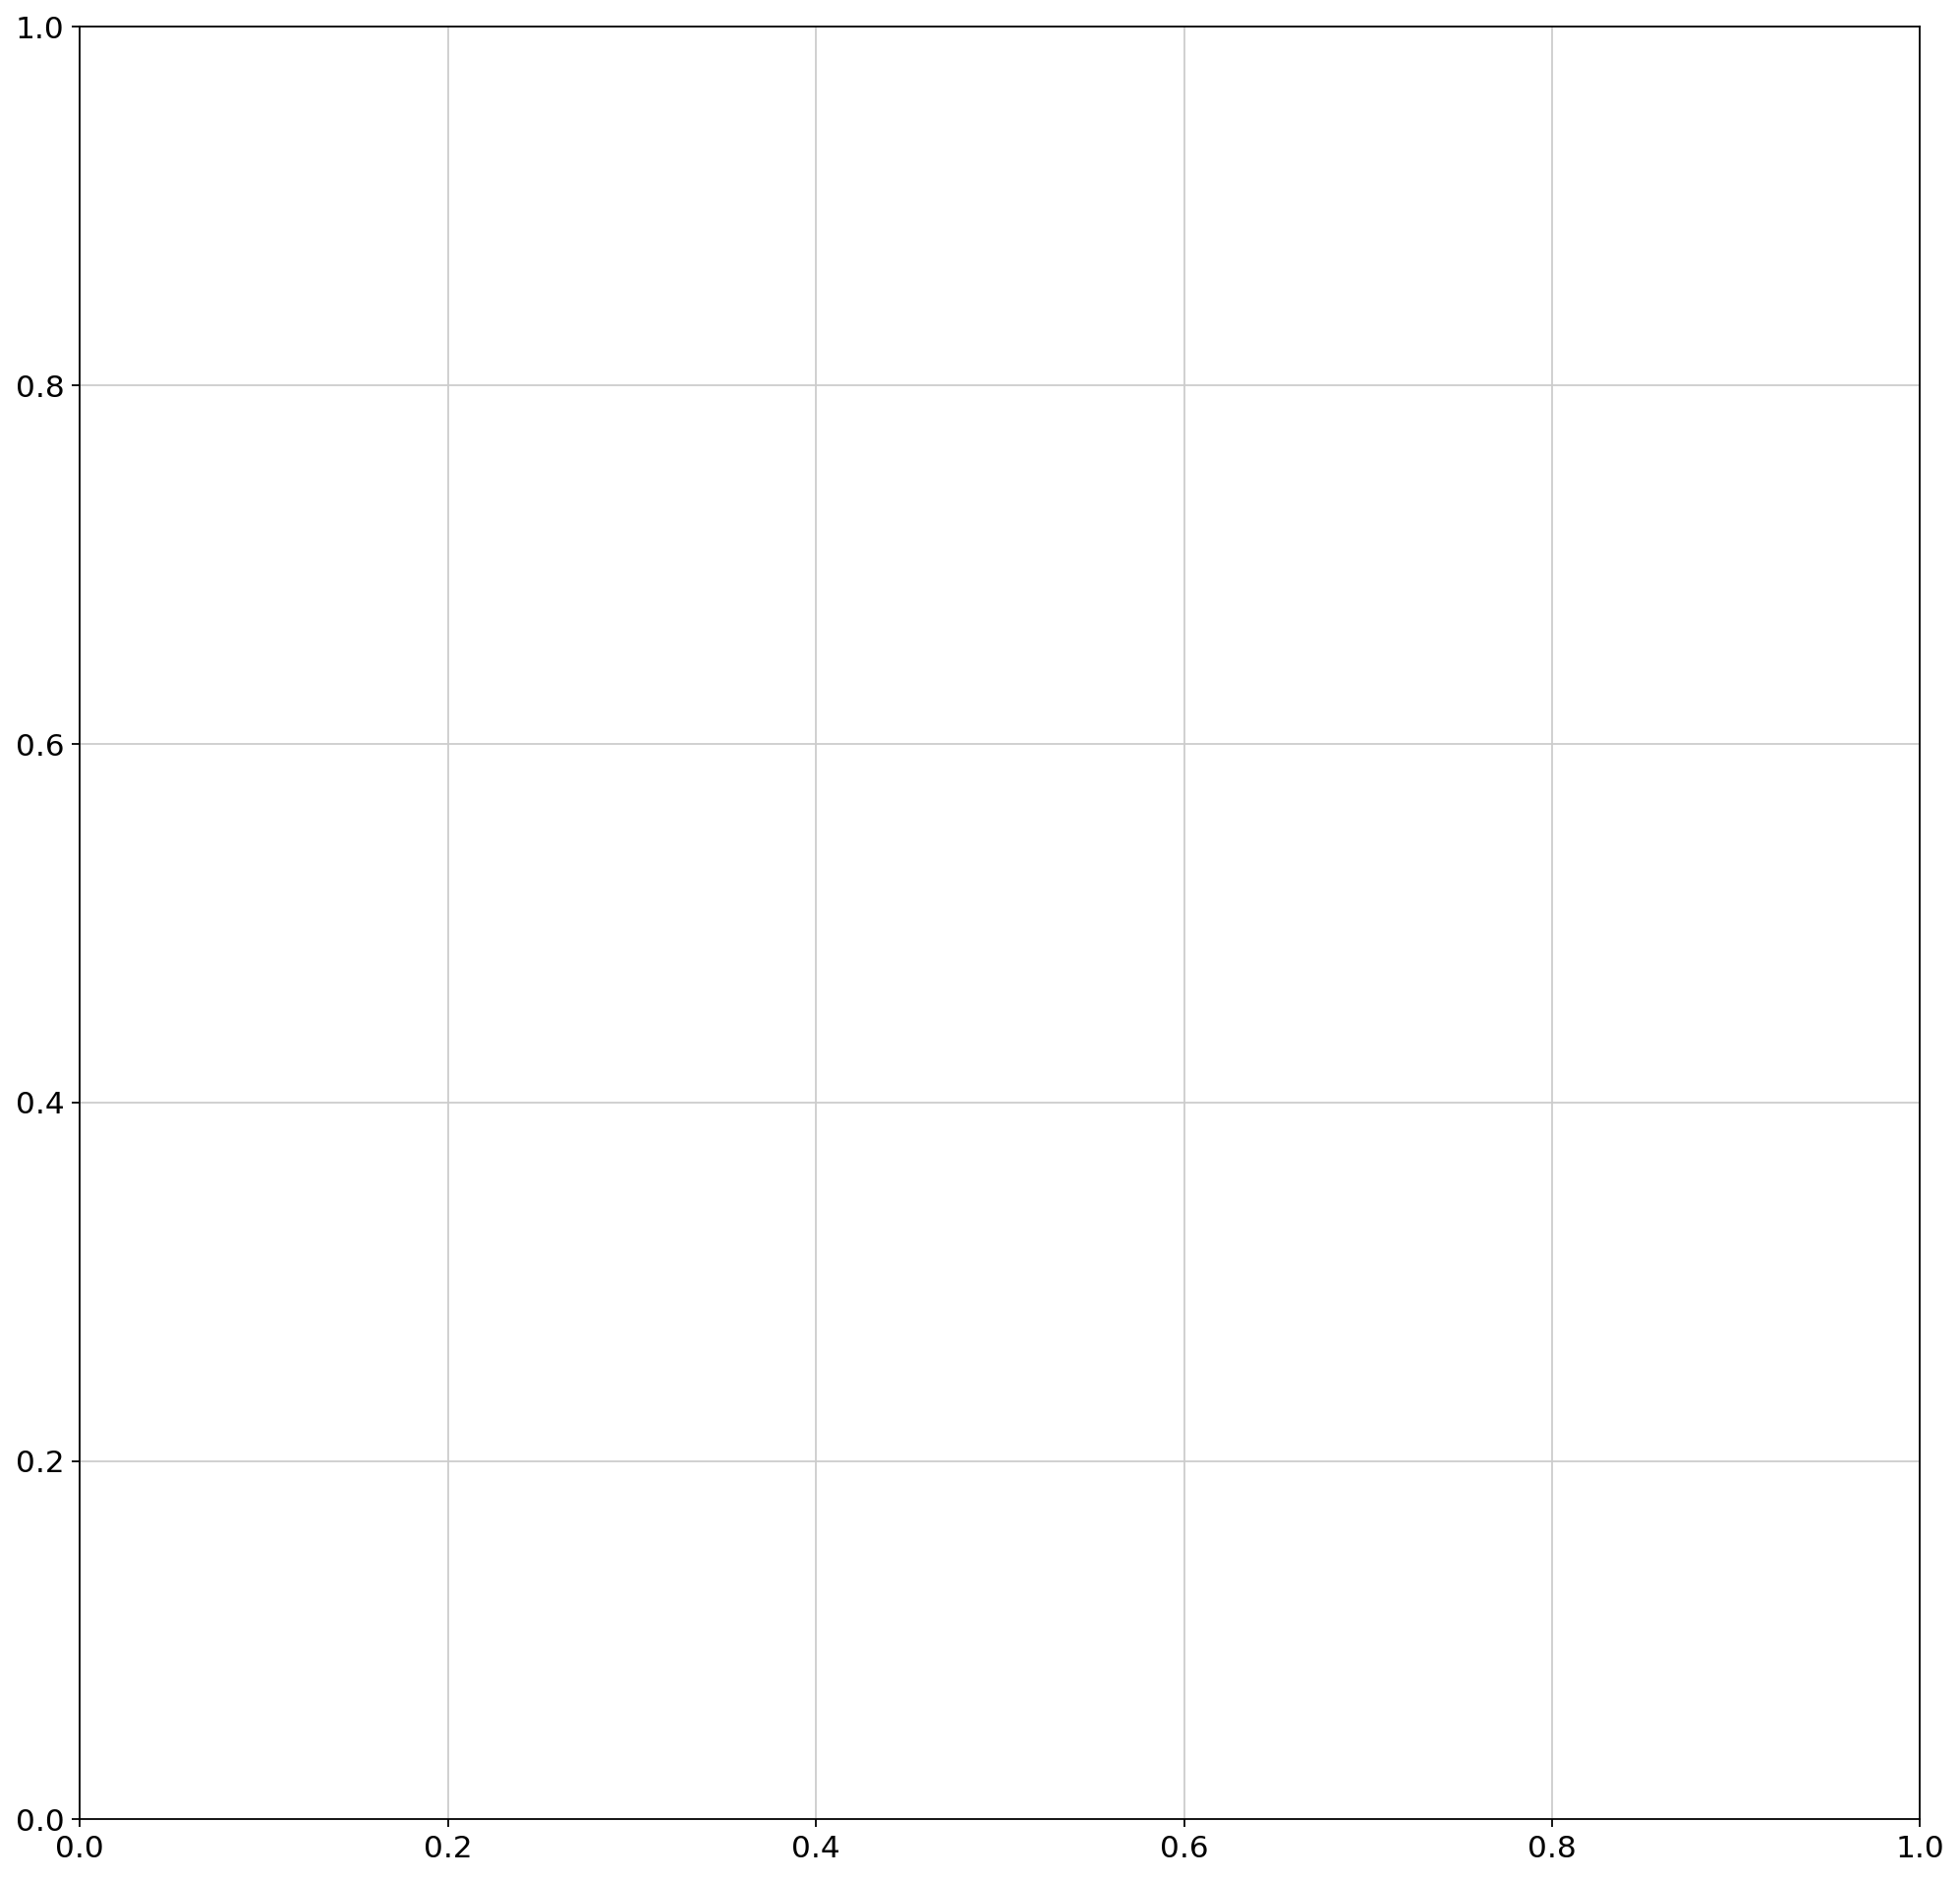

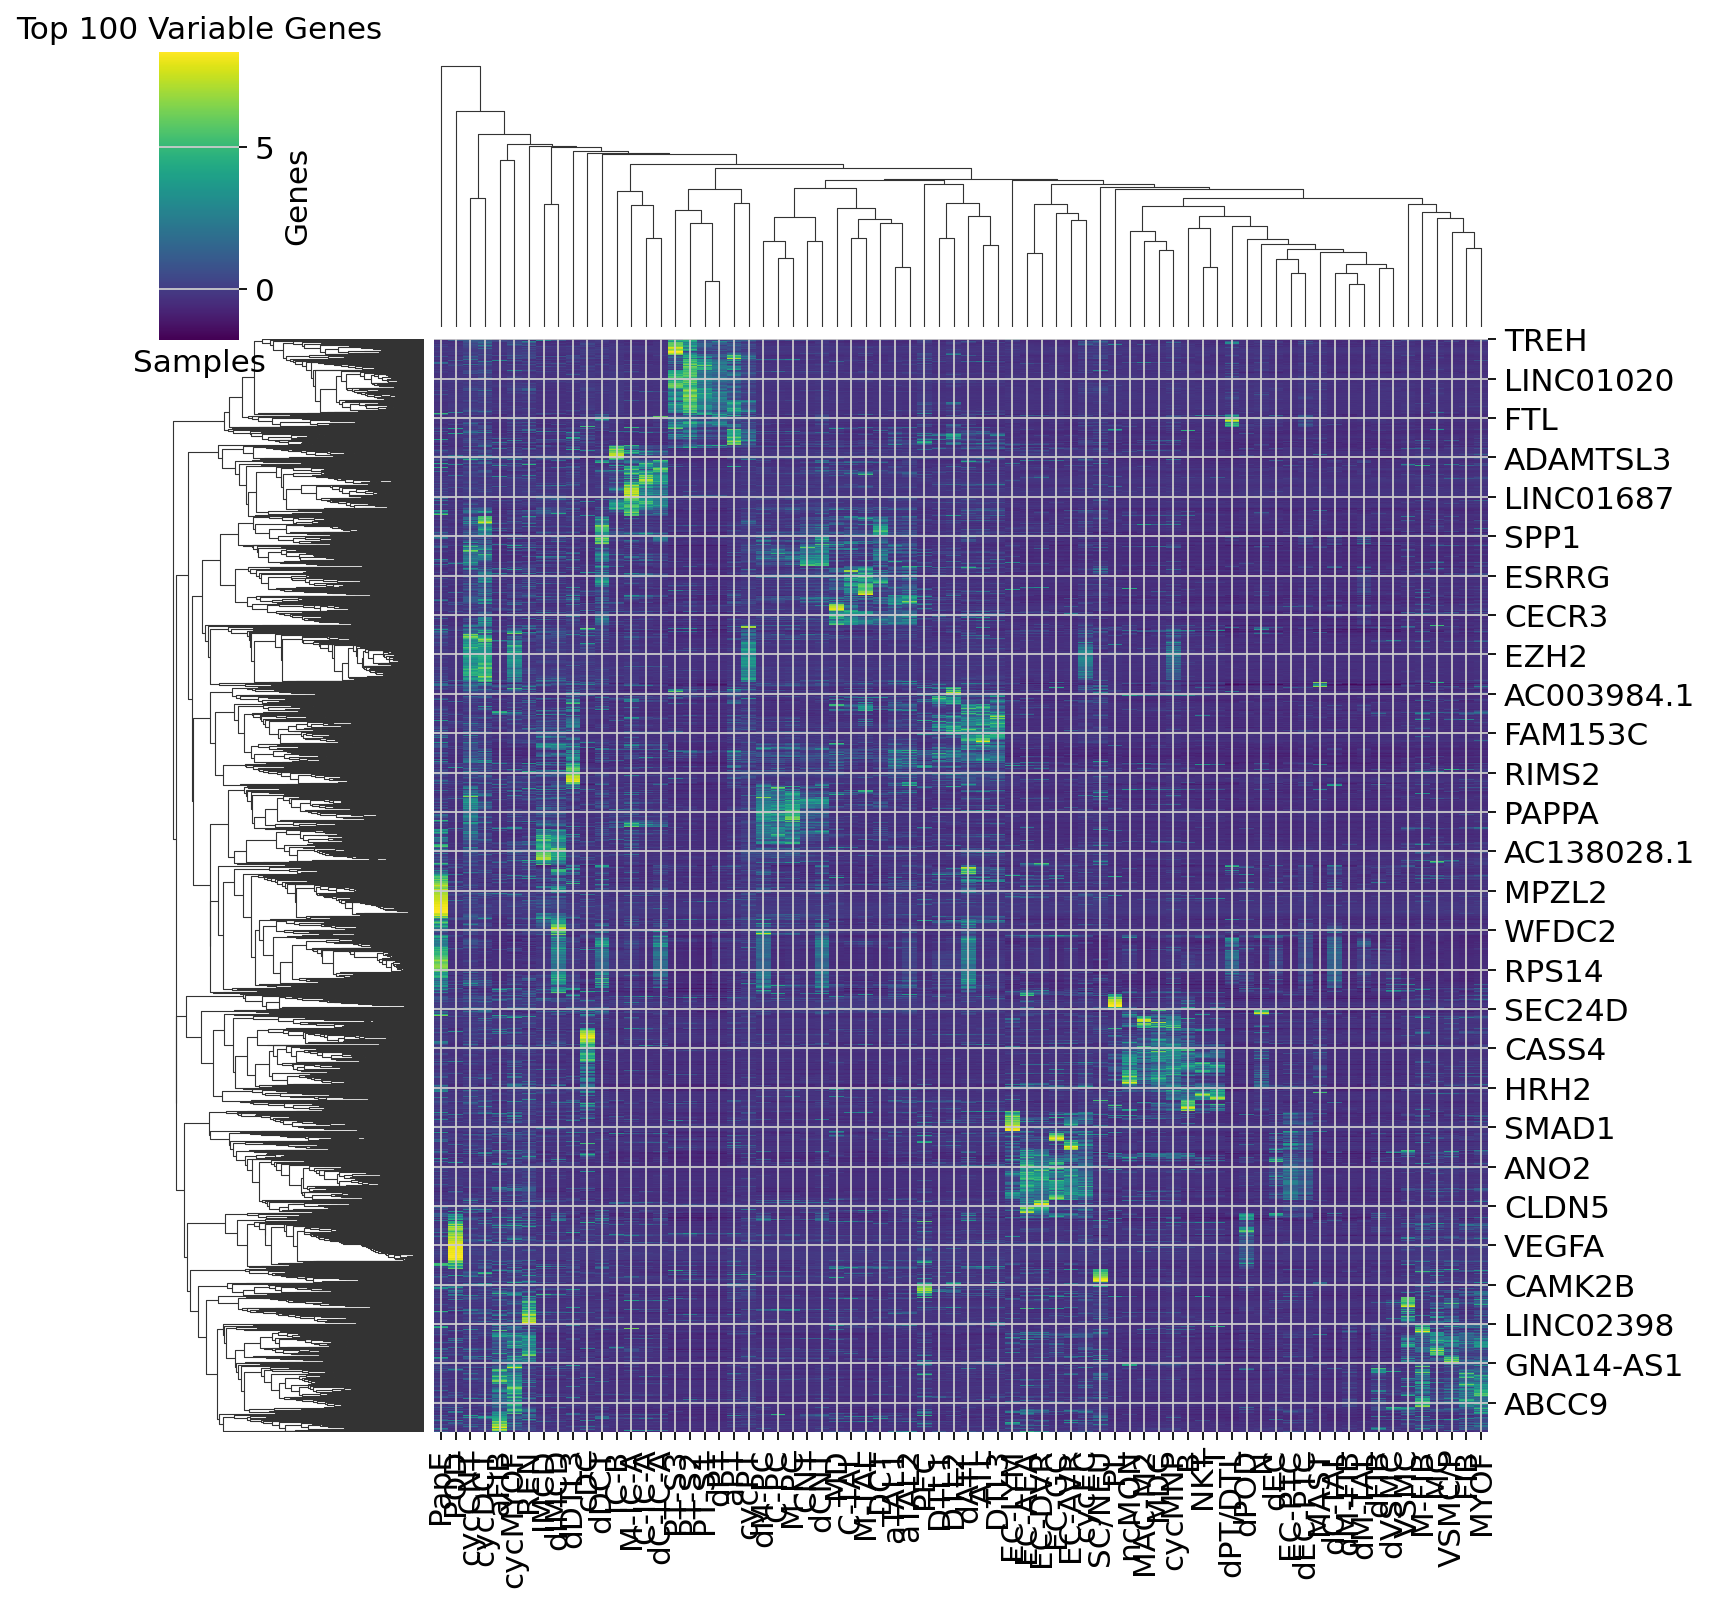

In [115]:
plt.subplots(figsize=(15, 15))
sns.clustermap(df.iloc[:, :-2], cmap='viridis', xticklabels=True)
plt.title('Top 100 Variable Genes')
plt.xlabel('Samples')
plt.ylabel('Genes')

In [116]:
df.shape

(3136, 74)

In [117]:
adata.obs['subclass.l2'].nunique()

74